# Model Training

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import shap

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay
)

os.makedirs('../models', exist_ok=True)

### 1. Loading Processed Splits and Preprocessor
We load the pre-split train and validation datasets along with the `preprocessor.joblib` pipeline created in Phase 2.

In [5]:
train_df = pd.read_csv('../data/processed/train.csv')
val_df = pd.read_csv('../data/processed/val.csv')
preprocessor = joblib.load('../models/preprocessor.joblib')

categorical_features = [
    'Shipping Mode', 'Customer Segment', 'Market', 'Order Region',
    'Department Name', 'Category Name', 'Type'
]

numerical_features = [
    'Order Item Quantity', 'Order Item Product Price', 'Order Item Discount Rate',
    'Order Item Discount', 'Order Item Total', 'Sales',
    'order_month', 'order_day', 'order_dow', 'order_hour',
    'is_weekend', 'is_domestic'
]

feature_cols = categorical_features + numerical_features
target = 'Late_delivery_risk'

X_train = preprocessor.transform(train_df[feature_cols])
y_train = train_df[target].values

X_val = preprocessor.transform(val_df[feature_cols])
y_val = val_df[target].values

print(f"X_train shape: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_val shape:   {X_val.shape}, y_val:   {y_val.shape}")

X_train shape: (126363, 81), y_train: (126363,)
X_val shape:   (27078, 81), y_val:   (27078,)


### 2. Model Training
All models use random_state=42 for exact reproducibility. Each model is trained and evaluated on the validation set one at a time, and its metrics are stored in `metrics_list`.


In [6]:
val_probs = {}
val_preds = {}
trained_models = {}
metrics_list = []

def evaluate(name, model):
    probs = model.predict_proba(X_val)[:, 1]
    preds = (probs >= 0.50).astype(int)

    trained_models[name] = model
    val_probs[name] = probs
    val_preds[name] = preds

    row = {
        'Model': name,
        'Accuracy': round(accuracy_score(y_val, preds), 4),
        'Precision': round(precision_score(y_val, preds), 4),
        'Recall': round(recall_score(y_val, preds), 4),
        'F1': round(f1_score(y_val, preds), 4),
        'ROC-AUC': round(roc_auc_score(y_val, probs), 4),
        'PR-AUC': round(average_precision_score(y_val, probs), 4)
    }
    metrics_list.append(row)
    print(pd.Series(row).to_string())


#### 2.1 Logistic Regression (baseline)


In [7]:
lr = LogisticRegression(max_iter=500, random_state=42)
lr.fit(X_train, y_train)
evaluate('Logistic Regression', lr)


Model        Logistic Regression
Accuracy                  0.6947
Precision                 0.8393
Recall                     0.539
F1                        0.6565
ROC-AUC                   0.7292
PR-AUC                    0.8035


#### 2.2 Decision Tree


In [8]:
dt = DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=42)
dt.fit(X_train, y_train)
evaluate('Decision Tree', dt)


Model        Decision Tree
Accuracy             0.708
Precision           0.8227
Recall              0.5869
F1                  0.6851
ROC-AUC             0.7566
PR-AUC              0.8161


#### 2.3 Random Forest


In [9]:
rf = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
evaluate('Random Forest', rf)


Model        Random Forest
Accuracy            0.7117
Precision            0.843
Recall              0.5741
F1                   0.683
ROC-AUC             0.7568
PR-AUC              0.8206


#### 2.4 XGBoost


In [10]:
xgb = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, eval_metric='logloss', random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train)
evaluate('XGBoost', xgb)


Model        XGBoost
Accuracy      0.7101
Precision     0.8375
Recall         0.576
F1            0.6825
ROC-AUC       0.7585
PR-AUC        0.8237


### 3. Validation Set Evaluation
We evaluate all models on the validation set across six metrics: Accuracy, Precision, Recall, F1, ROC-AUC, and PR-AUC. The results are exported to `reports/metrics.csv`.

In [ ]:
metrics_df = pd.DataFrame(metrics_list)
metrics_df.to_csv('../reports/metrics.csv', index=False)
print("Validation Metrics Comparison (Threshold = 0.50):")
print(metrics_df.to_string(index=False))


### 4. ROC and Precision-Recall Curves
Let's visualize the discrimination ability and precision-recall trade-offs across all models.

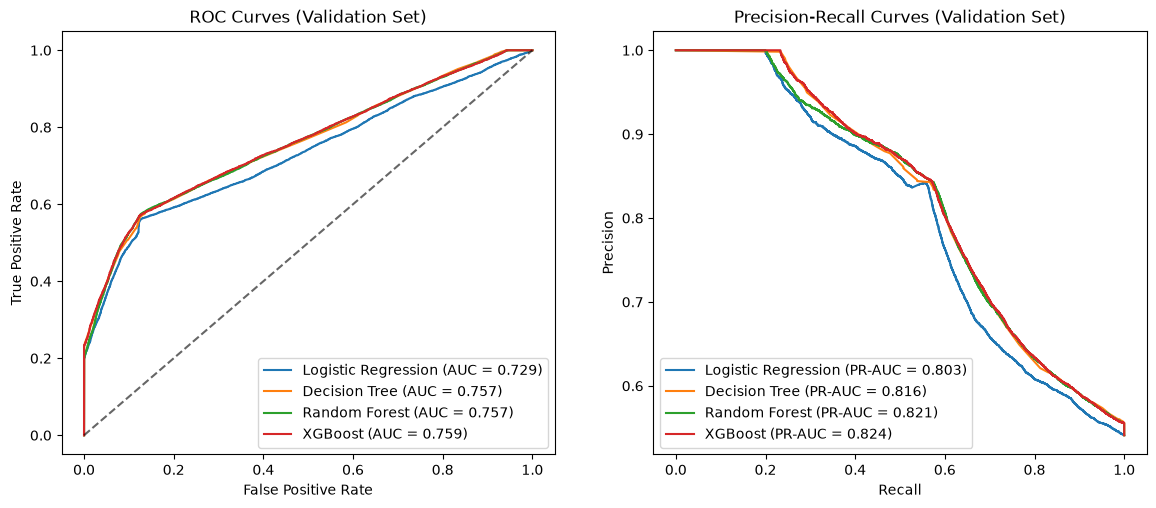

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for name in val_probs.keys():
    fpr, tpr, _ = roc_curve(y_val, val_probs[name])
    auc_val = roc_auc_score(y_val, val_probs[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.6)
axes[0].set_title('ROC Curves (Validation Set)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')

for name in val_probs.keys():
    prec, rec, _ = precision_recall_curve(y_val, val_probs[name])
    pr_auc = average_precision_score(y_val, val_probs[name])
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC = {pr_auc:.3f})")

axes[1].set_title('Precision-Recall Curves (Validation Set)')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')

plt.show()

### 5. Confusion Matrices
Let's inspect the distribution of True Positives, False Positives, True Negatives, and False Negatives at the standard 0.50 threshold.

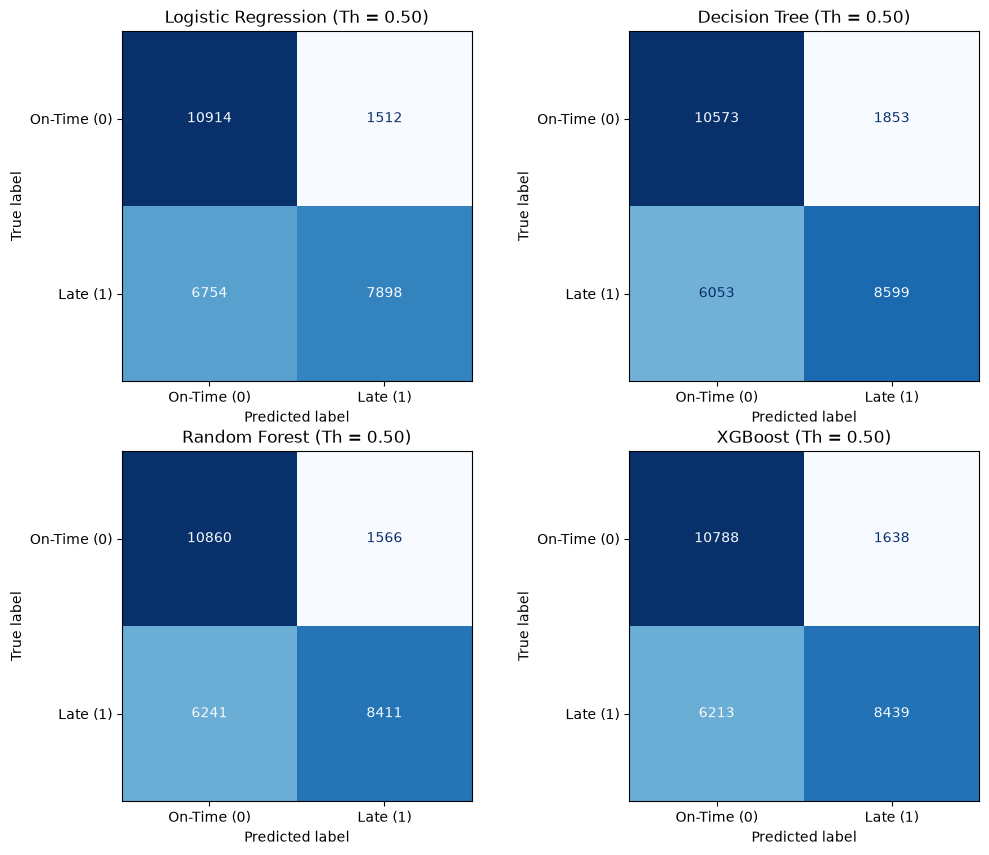

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, name in enumerate(val_probs.keys()):
    cm = confusion_matrix(y_val, val_preds[name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['On-Time (0)', 'Late (1)'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"{name} (Th = 0.50)")

plt.show()

### 6. Decision Threshold Tuning & Business Trade-Off
In late delivery prediction:
- **False Negative (Missed Late Order)**: Customer experiences unexpected delay, calls support, files complaints, cancels future business, and incurs delivery penalty costs. High business impact.
- **False Positive (False Alarm)**: Proactively flagged order undergoes priority warehouse picking, extra verification, or expedited carrier handoff. Low operational cost.

At `threshold = 0.50`, XGBoost achieves 83.7% precision but only 57.6% recall (missing 6,213 late deliveries out of 14,652).
Let's sweep thresholds from 0.25 to 0.60 to find an operating point that boosts Recall while maintaining solid Precision.

Precision-Recall Tradeoff across Decision Thresholds (XGBoost):
 Threshold  Accuracy  Precision  Recall     F1
      0.25    0.5678     0.5560  0.9988 0.7144
      0.30    0.5697     0.5578  0.9885 0.7131
      0.35    0.6078     0.5902  0.9003 0.7130
      0.40    0.6774     0.7032  0.6988 0.7010
      0.45    0.7084     0.8274  0.5827 0.6838
      0.50    0.7101     0.8375  0.5760 0.6825
      0.55    0.7107     0.8414  0.5734 0.6820
      0.60    0.7108     0.8435  0.5717 0.6815


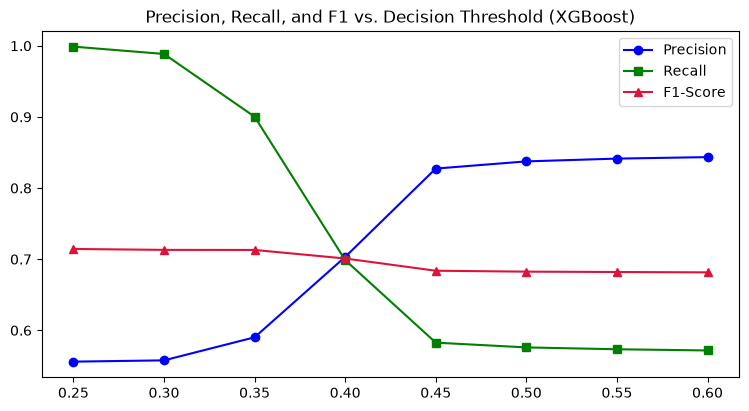

In [20]:
xgb_probs = val_probs['XGBoost']
thresholds = np.arange(0.25, 0.65, 0.05)
tradeoffs = []

for th in thresholds:
    th_preds = (xgb_probs >= th).astype(int)
    tradeoffs.append({
        'Threshold': round(th, 2),
        'Accuracy': round(accuracy_score(y_val, th_preds), 4),
        'Precision': round(precision_score(y_val, th_preds), 4),
        'Recall': round(recall_score(y_val, th_preds), 4),
        'F1': round(f1_score(y_val, th_preds), 4)
    })

tradeoff_df = pd.DataFrame(tradeoffs)
print("Precision-Recall Tradeoff across Decision Thresholds (XGBoost):")
print(tradeoff_df.to_string(index=False))

plt.figure(figsize=(9, 4.5))
plt.plot(tradeoff_df['Threshold'], tradeoff_df['Precision'], 'o-', label='Precision', color='blue')
plt.plot(tradeoff_df['Threshold'], tradeoff_df['Recall'], 's-', label='Recall', color='green')
plt.plot(tradeoff_df['Threshold'], tradeoff_df['F1'], '^-', label='F1-Score', color='crimson')
plt.title('Precision, Recall, and F1 vs. Decision Threshold (XGBoost)')

plt.legend()

plt.show()

**Chosen Threshold: `0.40`**
At `threshold = 0.40`:
- **Recall jumps from 57.6% to 69.9%** (catching an extra 1,800+ late orders).
- **Precision remains healthy at 70.3%**.
- **F1-Score reaches 0.7010** (higher than at 0.50).
This achieves the best balance between catching late orders and minimizing false alarms.

### 7. Feature Importance & SHAP Interpretability
Let's interpret what features XGBoost relies on to make predictions. We extract feature names from the `preprocessor` ColumnTransformer and generate a SHAP summary plot.

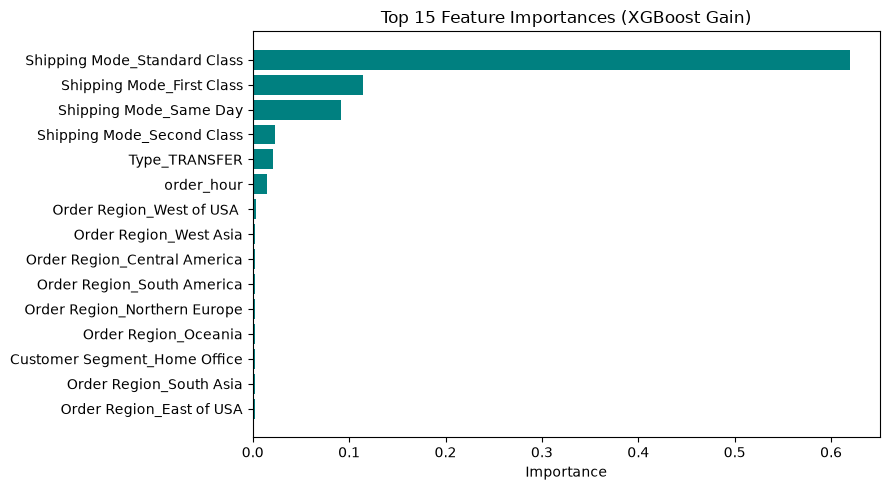

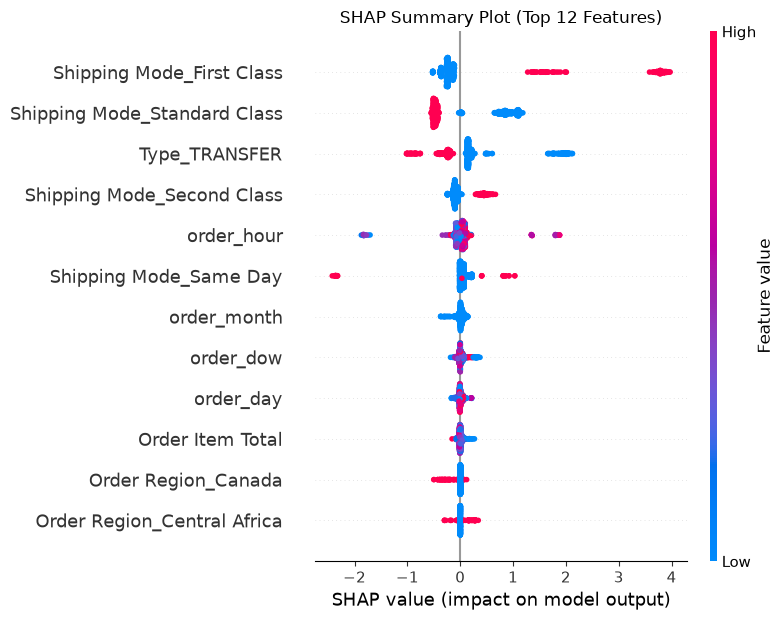

In [23]:
best_model = trained_models['XGBoost']

# Extract preprocessed feature names
cat_encoder = preprocessor.named_transformers_['cat']
cat_feature_names = cat_encoder.get_feature_names_out(categorical_features).tolist()
all_feature_names = cat_feature_names + numerical_features

# Feature Importances (Weight / Gain)
importances = best_model.feature_importances_
top_idx = np.argsort(importances)[::-1][:15]

plt.figure(figsize=(9, 5))
plt.barh([all_feature_names[i] for i in top_idx][::-1], importances[top_idx][::-1], color='teal')
plt.title('Top 15 Feature Importances (XGBoost Gain)')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('../reports/feature_importance.png', dpi=300)
plt.show()

# SHAP TreeExplainer
explainer = shap.TreeExplainer(best_model)
sample_val = X_val[:1000]
shap_vals = explainer(sample_val)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals.values, sample_val, feature_names=all_feature_names, max_display=12, show=False)
plt.title('SHAP Summary Plot (Top 12 Features)', fontsize=12)
plt.tight_layout()
plt.savefig('../reports/shap_summary.png', dpi=300)
plt.show()

### 8. Final Holdout Evaluation
We evaluate the chosen XGBoost model on data/holdout/holdout.csv (27,078 records from June 2017 to January 2018). This dataset was never touched during training or threshold tuning.

In [24]:
holdout_df = pd.read_csv('../data/holdout/holdout.csv')
X_holdout = preprocessor.transform(holdout_df[feature_cols])
y_holdout = holdout_df[target].values

holdout_probs = best_model.predict_proba(X_holdout)[:, 1]
holdout_preds_50 = (holdout_probs >= 0.50).astype(int)
holdout_preds_40 = (holdout_probs >= 0.40).astype(int)

holdout_results = [
    {
        'Split': 'Final Holdout (June 2017 - Jan 2018)',
        'Threshold': 0.50,
        'Accuracy': round(accuracy_score(y_holdout, holdout_preds_50), 4),
        'Precision': round(precision_score(y_holdout, holdout_preds_50), 4),
        'Recall': round(recall_score(y_holdout, holdout_preds_50), 4),
        'F1': round(f1_score(y_holdout, holdout_preds_50), 4),
        'ROC-AUC': round(roc_auc_score(y_holdout, holdout_probs), 4),
        'PR-AUC': round(average_precision_score(y_holdout, holdout_probs), 4)
    },
    {
        'Split': 'Final Holdout (June 2017 - Jan 2018)',
        'Threshold': 0.40,
        'Accuracy': round(accuracy_score(y_holdout, holdout_preds_40), 4),
        'Precision': round(precision_score(y_holdout, holdout_preds_40), 4),
        'Recall': round(recall_score(y_holdout, holdout_preds_40), 4),
        'F1': round(f1_score(y_holdout, holdout_preds_40), 4),
        'ROC-AUC': round(roc_auc_score(y_holdout, holdout_probs), 4),
        'PR-AUC': round(average_precision_score(y_holdout, holdout_probs), 4)
    }
]

holdout_metrics_df = pd.DataFrame(holdout_results)
holdout_metrics_df.to_csv('../reports/holdout_metrics.csv', index=False)
print("Final Holdout Evaluation Results:")
print(holdout_metrics_df.to_string(index=False))

print("\nConfusion Matrix on Holdout (Threshold = 0.40):")
print(confusion_matrix(y_holdout, holdout_preds_40))

Final Holdout Evaluation Results:
                               Split  Threshold  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
Final Holdout (June 2017 - Jan 2018)        0.5     0.719     0.8463  0.5978 0.7007   0.7703  0.8374
Final Holdout (June 2017 - Jan 2018)        0.4     0.666     0.6701  0.7743 0.7184   0.7703  0.8374

Confusion Matrix on Holdout (Threshold = 0.40):
[[ 6500  5680]
 [ 3363 11535]]


### 9.Production Pipeline
We bundle the `preprocessor` and the trained `XGBClassifier` into an end-to-end `Pipeline` and save it to `models/` with `joblib` for use in the Streamlit web application.

In [25]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', best_model)
])

# Save standalone model and complete end-to-end pipeline
joblib.dump(best_model, '../models/final_model.joblib')
joblib.dump(pipeline, '../models/pipeline.joblib')


metadata = {
    'categorical_features': categorical_features,
    'numerical_features': numerical_features,
    'all_feature_cols': feature_cols,
    'optimal_threshold': 0.40,
    'all_feature_names': all_feature_names
}
joblib.dump(metadata, '../models/model_metadata.joblib')

print("Saved:")
print(" - ../models/final_model.joblib")
print(" - ../models/pipeline.joblib")
print(" - ../models/model_metadata.joblib")

Saved:
 - ../models/final_model.joblib
 - ../models/pipeline.joblib
 - ../models/model_metadata.joblib
